# Ecuación del Calor en polares (2D)

Dado

$$
\Omega = \{(x,y) : r_1^2 < x^2 + y^2 < r_2^2\},
$$

y 

$$
f : \Omega \times [0, T] \to \mathbb{R}
$$

se quiere hallar

$$
u : \Omega \times [0,T] \to \mathbb{R}
$$

tal que satisface la ecuación del calor en dos dimensiones:

$$
\frac{\partial u}{\partial t} = a\,\Delta u + f(x,y,t), \qquad (x,y) \in \Omega,\; t \in (0,T).
$$

Con condiciones de contorno Dirichlet homogéneas:

$$
u(x,y,t) = 0 \qquad \text{en } \partial\Omega,\; t \in (0,T),
$$

y condición inicial

$$
u(x,y,0) = g(x,y), \qquad (x,y) \in \Omega.
$$

El laplaciano en polares es 

$$
\Delta u = \frac{\partial^2 u}{\partial r^2} + \frac{1}{r}\frac{\partial u}{\partial r} + \frac{1}{r^2}\frac{\partial^2 u}{\partial \theta^2}.
$$

## Objetivos y consignas

### Ejercicio 1
Deducir esquemas análogos a los de calor en coordenadas cartesianas, pero ahora para el problema en coordenadas polares. La idea es discretizar el laplaciano polar usando diferencias centradas en $r$ y $\theta$ y obtener sus versiones explícita e implícita.

### Ejercicio 2
Implementar ambos métodos para $r_1 > 0$, usando coordenadas polares, con pasos espaciales $\Delta r$ y $\Delta \theta$, paso temporal $\Delta t$, tiempo final $T$, coeficiente de difusión $a$, dato inicial $g$ y fuente $f$. El resultado debe visualizarse mediante un gráfico o una animación que muestre la evolución temporal de la solución.

### Ejercicio 3 (adicional)
Analizar la estabilidad de ambos esquemas mediante el método de von Neumann, "congelando" localmente el coeficiente $1/r_i$. Debe determinarse la condición sobre $\Delta t$ en función de $\Delta r$, $\Delta \theta$, $r$ y $a$ para que el esquema explícito sea estable, y verificar que el esquema implícito es incondicionalmente estable. Además, se recomienda corroborar experimentalmente ambos resultados.

### Referencia del esquema en cartesianas

Como base de comparación, se recuerdan los esquemas clásicos para la ecuación del calor en coordenadas cartesianas:

$$
\Delta_h u_{i,j} = \frac{u_{i+1,j} - 2u_{i,j} + u_{i-1,j}}{\Delta x^2} + \frac{u_{i,j+1} - 2u_{i,j} + u_{i,j-1}}{\Delta y^2}.
$$

y las versiones de avance temporal:

$$
\frac{u_{i,j}^{n+1} - u_{i,j}^{n}}{\Delta t} = a\,\Delta_h u_{i,j}^{n+1} + f_{i,j}^{n},
$$

para el esquema implícito, y

$$
\frac{u_{i,j}^{n+1} - u_{i,j}^{n}}{\Delta t} = a\,\Delta_h u_{i,j}^{n} + f_{i,j}^{n},
$$

para el esquema explícito.

### Datos de ejemplo sugeridos

Se proponen varios ejemplos para probar la implementación:

- $g(r,\theta) = 0$
- $g(r,\theta) = (r-r_1)(r_2-r)$
- $g(r,\theta) = \mathbf{1}_{[r_1,r_2]\times[\theta_1,\theta_2]}$

para la condición inicial, y

- $f(r,\theta,t)=0$
- $f(r,\theta,t)=(r-r_1)(r_2-r)$
- $f(r,\theta,t)=(r-r_1)(r_2-r)e^{-t}$

con distintos valores del $a$:

$$
a = 1, \qquad a = 0.1, \qquad a = 10.
$$

### Discretización en coordenadas polares

Dominio $r\in[r_{in},r_{out}]$, $\theta\in[0,2\pi)$ periódico.

- $r_i = r_{in} + i\Delta r$, $i=0,\ldots,N+1$, con $\Delta r=(r_{\rm out}-r_{\rm in})/(N+1)$,
- $\theta_j = j\Delta\theta$, $j=0,\ldots,N-1$, con $\Delta\theta=2\pi/N$,
- $t_n=n\Delta t$.

Notemos que estamos asumiendo una malla cuadrada, solo por simplicidad.

Con $U^n_{i,j}\approx u(r_i,\theta_j,t_n)$ y diferencias centradas,

$$
(L_hU)_{i,j}=\alpha_i^-U_{i-1,j}+\alpha_i^+U_{i+1,j}+\beta_i\,(U_{i,j-1}+U_{i,j+1})+\gamma_iU_{i,j},
$$

con

- $ \alpha_i^\pm=\frac{1}{\Delta r^2}\pm\frac{1}{2r_i\Delta r}, $
- $ \beta_i=\frac{1}{r_i^2\Delta\theta^2}, $
- $ \gamma_i=-\frac{2}{\Delta r^2}-2\beta_i. $


### Condiciones inicial y de contorno

- $U^0_{i,j}=g(r_i,\theta_j),$ 
- $U^n_{0,j}=U^n_{N+1,j}=0$. 
- En $\theta$ la malla es periódica: $U_{i,-1}=U_{i,N-1}$ y $U_{i,N}=U_{i,0}$.

### Esquema implícito

$$
\frac{U^{n+1}_{i,j}-U^n_{i,j}}{\Delta t}=a\,(L_hU^{n+1})_{i,j}+f(r_i,\theta_j,t_{n+1}),
$$

es decir, para $i=1,\ldots,N$:

$$
(1-a\Delta t\,\gamma_i)U^{n+1}_{i,j}-a\Delta t\,\alpha_i^+U^{n+1}_{i+1,j}-a\Delta t\,\alpha_i^-U^{n+1}_{i-1,j}
-a\Delta t\,\beta_i\,(U^{n+1}_{i,j+1}+U^{n+1}_{i,j-1})=U^n_{i,j}+\Delta t\,f^{n+1}_{i,j}.
$$

### Forma matricial

Con $U^n\in\mathbb{R}^{N\times N}$ (filas $i=1,\dots,N$, columnas $j=0,\dots,N-1$) y $F^{n+1}_{ij}=f(r_i,\theta_j,t_{n+1})$:

$$
A\,U^{n+1}+\mathcal{B}\,U^{n+1}\,T=U^n+\Delta t\,F^{n+1}.
$$

donde

$$
A=
\begin{pmatrix}
1-a\Delta t\gamma_1 & -a\Delta t\,\alpha_1^{+} & & \\
-a\Delta t\,\alpha_2^{-} & 1-a\Delta t\gamma_2 & -a\Delta t\,\alpha_2^{+} & \\
& \ddots & \ddots & \ddots \\
& & -a\Delta t\,\alpha_{N}^{-} & 1-a\Delta t\gamma_{N}
\end{pmatrix},
$$

$$
T=-a\Delta t
\begin{pmatrix}
0 & 1 & & & 1 \\
1 & 0 & 1 & & \\
& \ddots & \ddots & \ddots & \\
& & 1 & 0 & 1 \\
1 & & & 1 & 0
\end{pmatrix},
$$

y $\mathcal{B}=\operatorname{diag}(\beta_1,\dots,\beta_{N})$. Es importante notar que los $1$ en las esquinas de $T$ ($T_{1,N}=T_{N,1}$) cierran la periodicidad en $\theta$. En $A$ los vecinos $i=0,N+1$ valen $0$ (Dirichlet homogéneo) y por eso no aparecen.

### Paso temporal con Kronecker

Con $u^n=\mathrm{vec}(U^n)\in\mathbb{R}^{N^2}$ (apilando columnas, la entrada $(i,j)$ queda en la posición $i+jN$) y $T^T=T$:

$$
K\,u^{n+1}=u^n+\Delta t\,f^{n+1},\qquad
K=I_N\otimes A+T\otimes\mathcal{B}\in\mathbb{R}^{N^2\times N^2}.
$$

$K$ es bloque-tridiagonal periódica, con bloques de $N\times N$:

$$
K=
\begin{pmatrix}
A & -a\Delta t\,\mathcal{B} & & -a\Delta t\,\mathcal{B} \\
-a\Delta t\,\mathcal{B} & A & -a\Delta t\,\mathcal{B} & \\
& \ddots & \ddots & \ddots \\
-a\Delta t\,\mathcal{B} & & -a\Delta t\,\mathcal{B} & A
\end{pmatrix}.
$$

$K$ no depende de $n$, así que se factoriza una sola vez.

### Esquema implícito


$$
\frac{U^{n+1}_{i,j}-U^n_{i,j}}{\Delta t}=a\,(L_hU^{n+1})_{i,j}+f(r_i,\theta_j,t_{n+1}),
$$

es decir, para $i=1,\ldots,N$:

$$
U^{n+1}_{i,j} = (1 + a \Delta t \gamma_i )U_{i,j}^{n} + a \Delta t \alpha_i^-U_{i-1,j}^{n} + a \Delta t \alpha_i^+U_{i+1,j}^{n} + a \Delta t \beta_i\,(U_{i,j-1}^{n} + U_{i,j+1}^{n}) + \Delta t f^{n+1}_{i,j} .
$$

matricialmente tenemos

$$ U^{n+1} = A U^{n} + B U^{n} T + \delta t F^{n} $$

donde las matrices son como antes salvo que T tiene el "signo" opuesto y $A$ es de la forma

$$
A=
\begin{pmatrix}
1 + a\Delta t\gamma_1 & a\Delta t\,\alpha_1^{+} & & \\
a\Delta t\,\alpha_2^{-} & 1 + a\Delta t\gamma_2 & a\Delta t\,\alpha_2^{+} & \\
& \ddots & \ddots & \ddots \\
& & a\Delta t\,\alpha_{N}^{-} & 1 + a\Delta t\gamma_{N}
\end{pmatrix}.
$$



In [1]:
using LinearAlgebra, SparseArrays
using CairoMakie

In [2]:
# Parámetros del dominio y de la malla
const r1, r2 = 1.0, 2.0          
const N      = 128                
const dt     = 1e-3
const Tfinal = 0.5
const nsteps = round(Int, Tfinal / dt)

# Condiciones iniciales g(r,θ)
g_zero(r, θ)  = 0.0
g_parab(r, θ) = (r - r1) * (r2 - r)

# Indicadora de un rectangulito [ra,rb]×[θa,θb] 
const ra, rb = 1.25, 1.75
const θa, θb = π/4, π/2
g_ind(r, θ) = (ra ≤ r ≤ rb && θa ≤ θ ≤ θb) ? 1.0 : 0.0


# Fuentes f(r,θ,t)
f_zero(r, θ, t)  = 0.0
f_parab(r, θ, t) = (r - r1) * (r2 - r)
f_exp(r, θ, t)   = (r - r1) * (r2 - r) * exp(-t)

f_exp (generic function with 1 method)

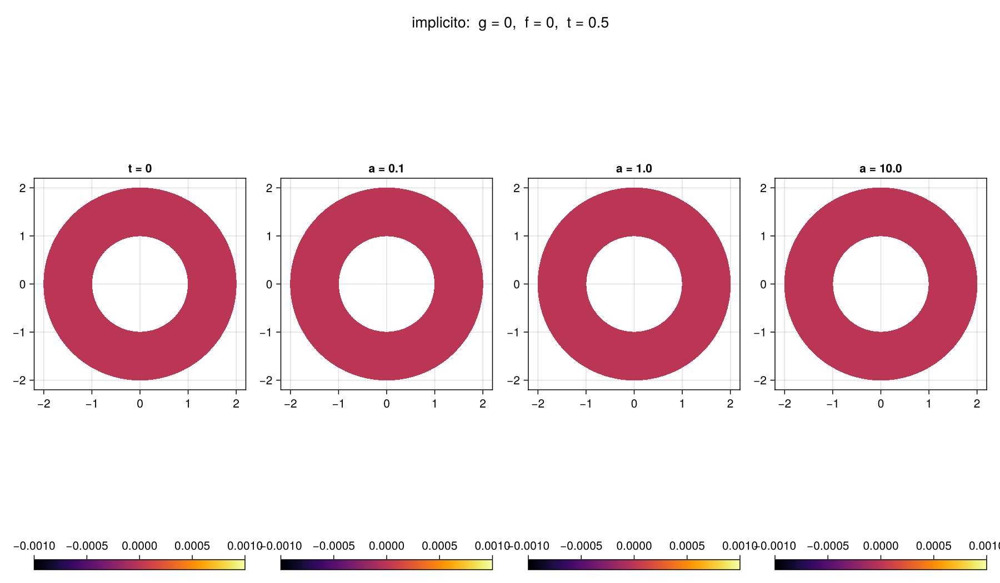

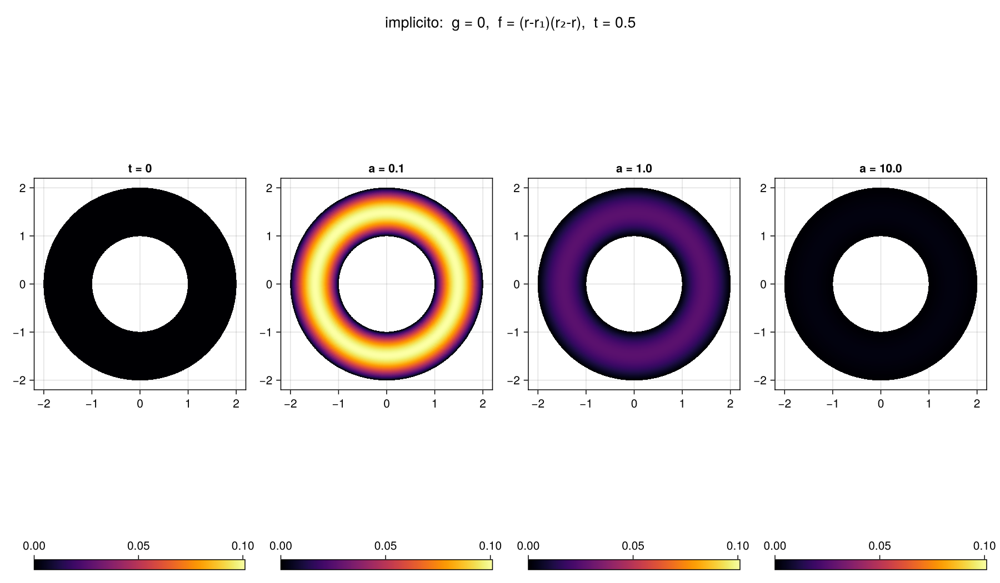

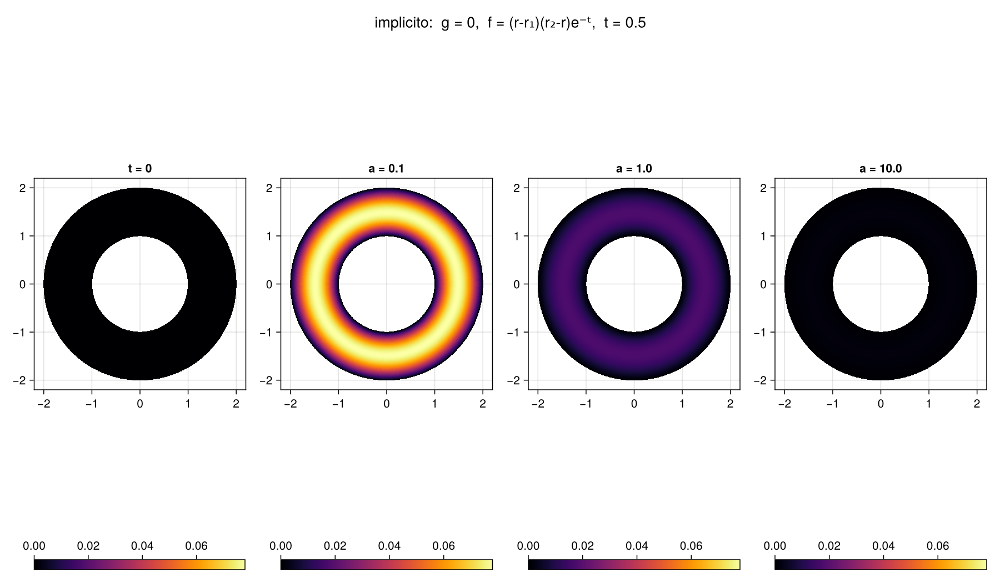

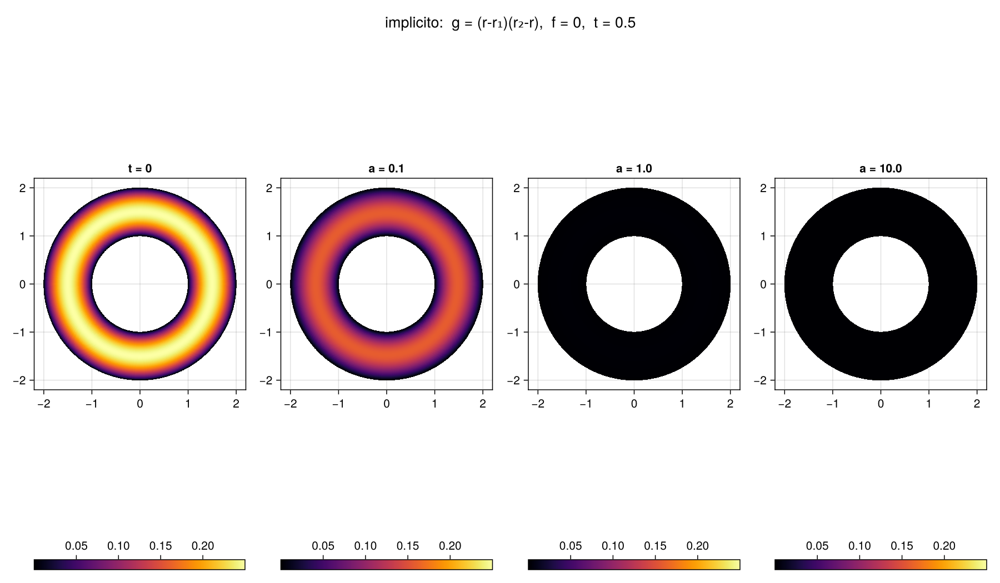

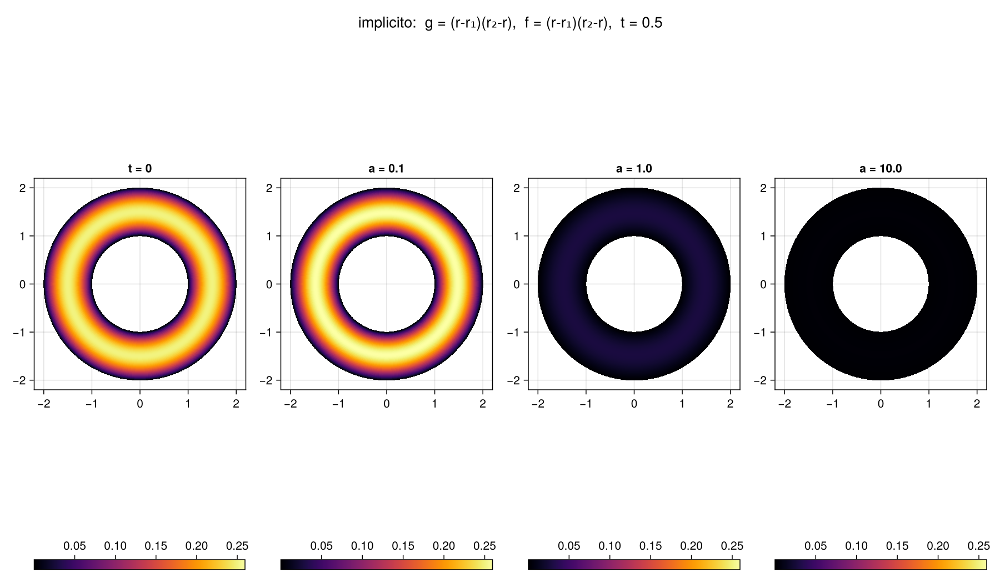

...

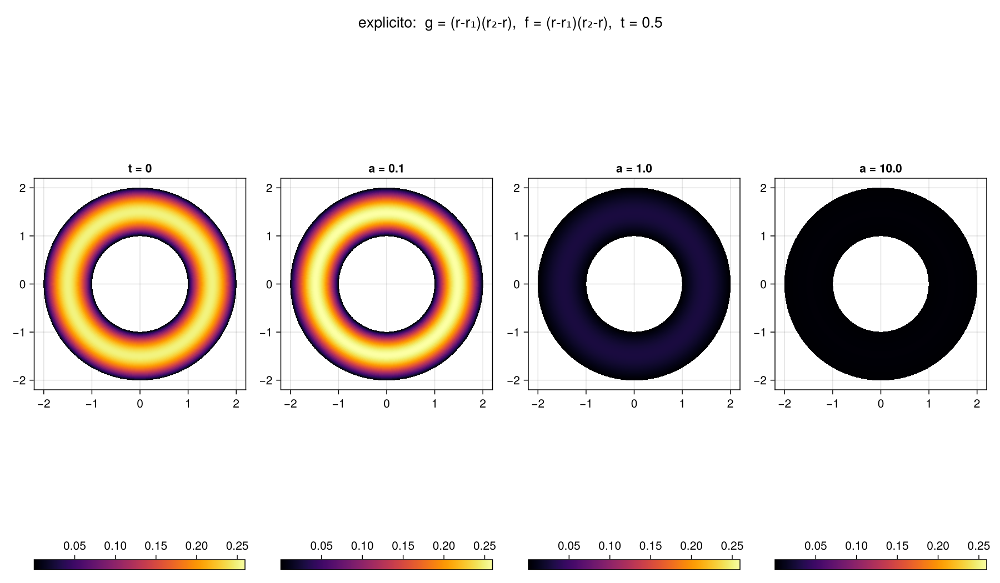

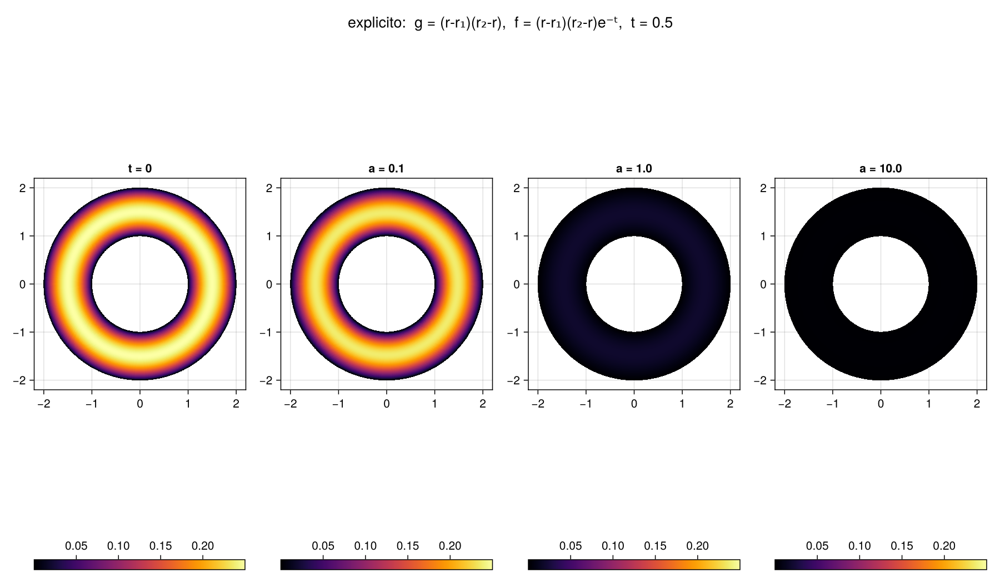

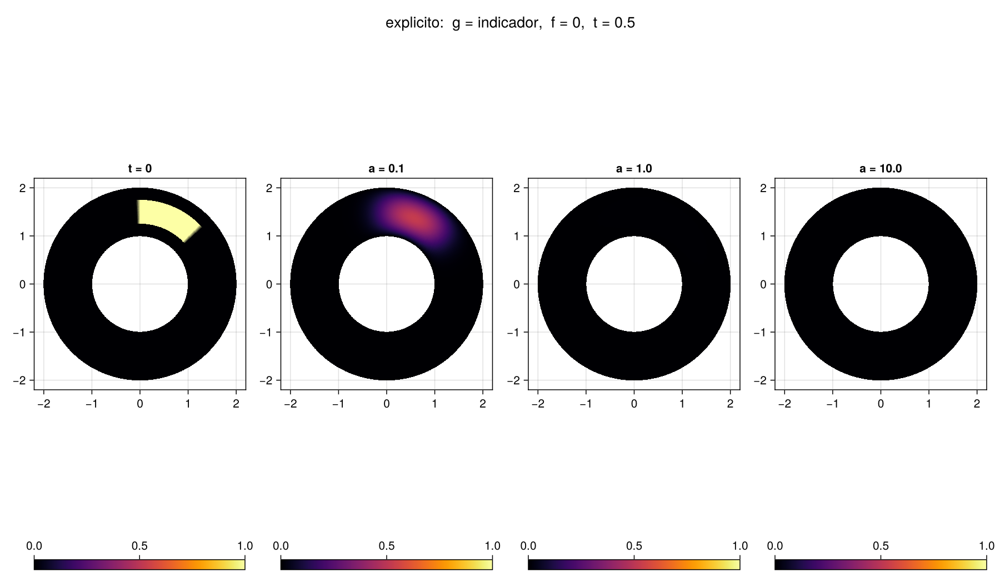

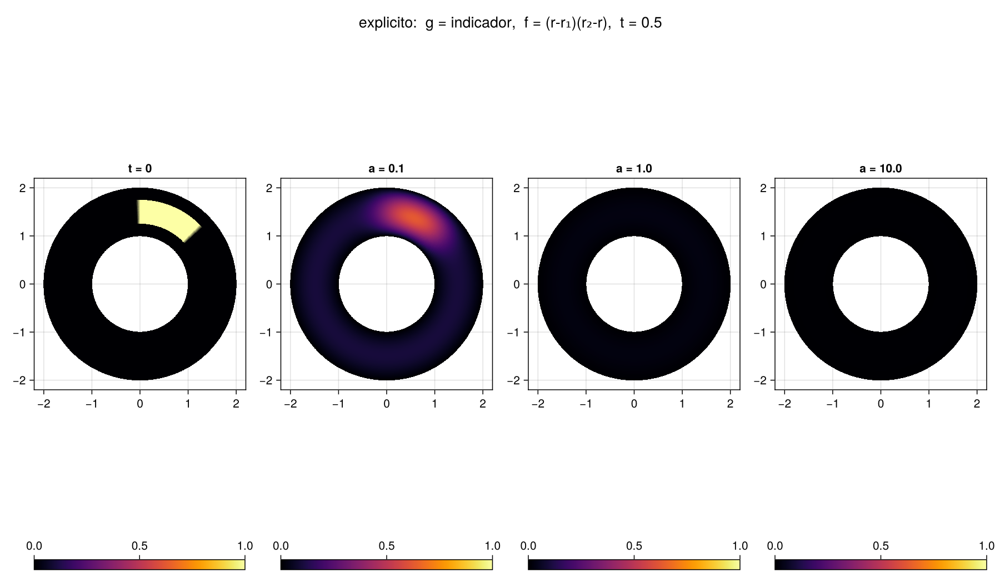

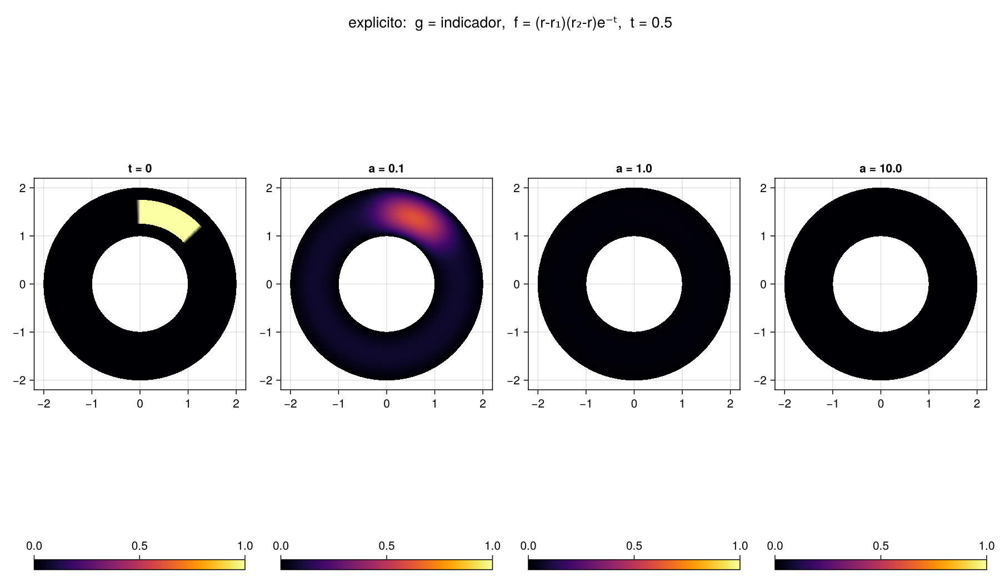

In [ ]:
# Construcción de K del método implícito
function build_K_implicito(rin, rout, N, a, dt)
    dr = (rout - rin) / (N + 1)
    dθ = 2π / N
    r  = [rin + i*dr for i in 1:N]       

    # @. actua coordenada a coordenada (vectoriza)    
    αp = @. 1/dr^2 + 1/(2*r*dr)
    αm = @. 1/dr^2 - 1/(2*r*dr)
    β  = @. 1/(r^2 * dθ^2)
    γ  = @. -2/dr^2 - 2*β

    # Elementos de la diagonal que acompañan a U_{i,j}^{n+1}
    main = @. 1 - a*dt*γ
    
    # Supradiagonal
    sup  = -a*dt .* αp[1:end-1]                  # A[i,i+1]
    
    # Subdiagonal
    sub  = -a*dt .* αm[2:end]                    # A[i,i-1]
    
    # OBS: 1:end-1 y 2:end es para que matcheen las dimensiones.

    # Arma una matriza esparsa (en este caso no completa lo que hay fuera de la diagonal)
    A = spdiagm(-1 => sub, 0 => main, 1 => sup)  # N×N
    B = spdiagm(β)                               # N×N

    # T
    T0 = spdiagm(-1 => ones(N-1), 1 => ones(N-1)) +
         sparse([1, N], [N, 1], [1.0, 1.0], N, N) 
    T  = -a*dt * T0

    K = kron(sparse(I, N, N), A) + kron(T, B)
    return K, A, B, T, r
end

# Construcción de K del método implícito
function build_ex2452689-plicito(rin, rout, N, a, dt)
    dr = (rout - rin) / (N + 1)
    dθ = 2π / N
    r  = [rin + i*dr for i in 1:N]       

    # @. actua coordenada a coordenada (vectoriza)    
    αp = @. 1/dr^2 + 1/(2*r*dr)
    αm = @. 1/dr^2 - 1/(2*r*dr)
    β  = @. 1/(r^2 * dθ^2)
    γ  = @. -2/dr^2 - 2*β

    # Elementos de la diagonal que acompañan a U_{i,j}^{n+1}
    main = @. 1 + a*dt*γ
    
    # Supradiagonal
    sup  = a*dt .* αp[1:end-1]                  # A[i,i+1]
    
    # Subdiagonal
    sub  = a*dt .* αm[2:end]                    # A[i,i-1]
    
    # OBS: 1:end-1 y 2:end es para que matcheen las dimensiones.

    # Arma una matriza esparsa (en este caso no completa lo que hay fuera de la diagonal)
    A = spdiagm(-1 => sub, 0 => main, 1 => sup)  # N×N
    B = spdiagm(β)                               # N×N

    # T
    T0 = spdiagm(-1 => ones(N-1), 1 => ones(N-1)) +
         sparse([1, N], [N, 1], [1.0, 1.0], N, N) 
    T  = a*dt * T0

    return A, B, T, r
end

# Simulación
function simulate_implicito(g, f, a; N=N, dt=dt, nsteps=nsteps, rin=r1, rout=r2,
                  save_every=nsteps)

    K, A, B, T, r = build_K_implicito(rin, rout, N, a, dt)
    θ = [j * 2π / N for j in 0:N-1]

    U    = [g(ri, θj) for ri in r, θj in θ]       # N×N, filas = i, columnas = j
    fact = lu(K)                                  # se factoriza una sola vez
    
    # Arma vector "basura" del mismo tamaño.
    u    = similar(vec(U))

    # guardamos cada paso en res, en primer lugar tenemos el dato inicial.
    res = Dict{Int,Matrix{Float64}}(0 => copy(U))
    for n in 0:nsteps-1
        t  = (n + 1) * dt                         
        F  = [f(ri, θj, t) for ri in r, θj in θ]
        rhs = vec(U .+ dt .* F)
        ldiv!(u, fact, rhs)
        U = copy(reshape(u, N, N))
        if (n + 1) % save_every == 0
            res[n+1] = copy(U)
        end
    end
    return r, θ, U, res
end


# Simulación explícita
function simulate_explicito(g, f, a; N=N, dt=dt, nsteps=nsteps, rin=r1, rout=r2,
                            save_every=nsteps)
   
    dr   = (rout - rin) / (N + 1)
    dθ   = 2π / N

    A, B, T, r = build_explicito(rin, rout, N, a, dt)
    θ = [j * dθ for j in 0:N-1]

    U   = [g(ri, θj) for ri in r, θj in θ]
    res = Dict{Int,Matrix{Float64}}(0 => copy(U))

    for n in 0:nsteps-1
        t = n * dt                                    
        F = [f(ri, θj, t) for ri in r, θj in θ]
        U = A*U + B*U*T + dt .* F                     
        if save_every > 0 && (n + 1) % save_every == 0
            res[n+1] = copy(U)
        end
    end
    return r, θ, U, res
end

# Resulta que para el explícito vamos a tener que refinar mas en el tiempo si no simulate_explicito 
# Más aún, va a depender de a
function simulate_explicito_a(g, f, a; Tf=Tfinal, kwargs...)
    dr = (r2 - r1) / (N + 1)
    dθ = 2π / N
    βmax  = 1 / ((r1 + dr)^2 * dθ^2)
    dtmax = 0.9 / (2*a*(1/dr^2 + βmax))
    ns = ceil(Int, Tf / dtmax)
    simulate_explicito(g, f, a; dt=Tf/ns, nsteps=ns, save_every=ns, kwargs...)
end


# Gráficos: se agregan bordes Dirichlet (ceros) y se cierra θ
function to_cartesian(r, θ, U, rin, rout)
    dr  = (rout - rin) / (N + 1)
    rf  = vcat(rin, r, rout)                      # N+2 radios
    θf  = vcat(θ, 2π)                             # cierra la vuelta
    Uf  = zeros(N + 2, N + 1)
    Uf[2:N+1, 1:N] .= U
    Uf[2:N+1, N+1] .= U[:, 1]                     # j = N ≡ j = 0
    X = [ri * cos(θj) for ri in rf, θj in θf]
    Y = [ri * sin(θj) for ri in rf, θj in θf]
    return X, Y, Uf
end

function plot_field!(ax, r, θ, U; colorrange=nothing)
    X, Y, Uf = to_cartesian(r, θ, U, r1, r2)
    lo, hi = colorrange === nothing ? extrema(Uf) : colorrange
    if hi - lo < 1e-12                      # campo constante (p.ej. todo cero)
        lo, hi = lo - 1e-3, hi + 1e-3
    end
    sf = surface!(ax, X, Y, zeros(size(X)); color=Uf, shading=NoShading,
                  colormap=:inferno, colorrange=(lo, hi))
    return sf
end

# Casos de prueba
gs = [("g = 0", g_zero), ("g = (r-r₁)(r₂-r)", g_parab), ("g = indicador", g_ind)]
fs = [("f = 0", f_zero), ("f = (r-r₁)(r₂-r)", f_parab), ("f = (r-r₁)(r₂-r)e⁻ᵗ", f_exp)]
as = [0.1, 1.0, 10.0]


# Elige el método y devuelve (r, θ, U_final, res) a tiempo Tfinal
function simular(metodo, g, f, a)
    if metodo == :implicito
        return simulate_implicito(g, f, a)               # dt y nsteps por defecto
    elseif metodo == :explicito
        return simulate_explicito_a(g, f, a)   # dt ajustado por estabilidad
    else
        error("método desconocido: $metodo (usá :implicito o :explicito)")
    end
end

function run_case(metodo, gname, g, fname, f)
    fig = Figure(size=(1200, 700))
    Label(fig[0, 1:length(as)+1],
          "$metodo:  $gname,  $fname,  t = $Tfinal", fontsize=18)

    # Soluciones a tiempo final para cada a (r y θ no dependen de a ni del método)
    sims    = [simular(metodo, g, f, a) for a in as]
    r, θ    = sims[1][1], sims[1][2]
    results = [s[3] for s in sims]

    # Condición inicial calculada directamente, sin simular
    U0 = [g(ri, θj) for ri in r, θj in θ]

    allU = vcat(vec(U0), reduce(vcat, vec.(results)))
    cr = extrema(allU)                       # escala de color común

    ax = Axis(fig[1, 1], aspect=DataAspect(), title="t = 0")
    sf = plot_field!(ax, r, θ, U0; colorrange=cr)
    Colorbar(fig[2, 1], sf, vertical=false)

    for (k, (a, U)) in enumerate(zip(as, results))
        ax = Axis(fig[1, k+1], aspect=DataAspect(), title="a = $a")
        sf = plot_field!(ax, r, θ, U; colorrange=cr)
        Colorbar(fig[2, k+1], sf, vertical=false)
    end
    return fig
end

CairoMakie.activate!(type = "png", px_per_unit = 1.5)

# Todas las combinaciones con ambos métodos (18 figuras)
for metodo in (:implicito, :explicito)
    for (gname, g) in gs, (fname, f) in fs
        display(run_case(metodo, gname, g, fname, f))
    end
end